# scKNIFE: 36,721-cell tutorial

## Installation

Use Python 3.9.21. From the cloned repository, install the tutorial environment:

```bash
python -m pip install -e ".[tutorial]"
```

In [1]:
%matplotlib inline
import scknife
from importlib.metadata import version
print(version("scknife"))

Matplotlib is building the font cache; this may take a moment.


0.1.0


## Run scKNIFE


### Start with raw counts

This tutorial uses cohort 2 of the Bassez et al. breast cancer dataset. Download the [raw counts and metadata](https://lambrechtslab.sites.vib.be/en/single-cell) and place both files in `tutorial/inputs/` (`1867-counts_cells_cohort2.rds` and `1871-BIOKEY_metaData_cohort2_web.csv`). Reading the RDS requires R with the Matrix package.

In [2]:
import scknife

sample = scknife.tutorial.sample_bassez(n_cells=None, seed=42)

This selects all 36,721 TNBC cells in the dataset, including 15,773 pretreatment and 20,948 on-treatment cells from six patients.

### Build or load a graph

Build a graph from the [individual collections](../docs/tutorials/../graphs.md), or load a supplied graph. The example uses Version 1; Version 2 adds Human-GEM.

In [3]:
# graph = scknife.tutorial.build_graph(["hallmark", "enrichr_go", "rxn_by_gene", "task_by_rxn"])
graph = scknife.tutorial.load_graph("graphs/version_1/unified_graph.graphml")
# graph = scknife.tutorial.load_graph("graphs/version_2/unified_graph.graphml")

| Collection | Relationships it contributes |
|---|---|
| `hallmark` | Genes linked to MSigDB Hallmark programs for factor interpretation. |
| `enrichr_go` | Genes linked to functional process sets. Check the set names when choosing a process to study. |
| `rxn_by_gene` | Gene–reaction associations for interpreting metabolic activity. |
| `task_by_rxn` | Metabolic task-support relationships. Pair with `rxn_by_gene` for reaction context. |
| `cellchat` | Ligand and receptor components linked through signaling interactions. |
| `markers` | Marker genes linked to cell types, including breast epithelial and tumor-microenvironment populations. |
| `cell_state` | Genes linked to state or population programs from the breast-tissue CellMarker panel. |

**Marker set.** The supplied breast/TNBC marker collection includes general immune and stromal markers as well as breast-context markers. For a different tumor—for example, lung cancer—select human lung records for the relevant cancer type in [CellMarker 2.0](https://bio-bigdata.hrbmu.edu.cn/CellMarker2.0/index.html), or use a published marker panel for that tumor. The [graph guide](../docs/tutorials/../graphs.md#marker-set) shows how to use those gene–cell-type pairs in place of the supplied marker collection. These relationships inform the graph; existing cell labels stay in the metadata.

Use the chosen graph for both tuning and fitting. For the displayed GO, MEAI and signaling results, use Version 1.

### Hyperparameter optimization

In [4]:
adata, params = scknife.tutorial.optimize_hyperparameters(
    sample, graph, ranks=(8, 16, 24), subset=2000, validation=500, seed=42
)
params

{'k': 24, 'lambda_reg': 0.1, 'beta_W': 0.001, 'beta_H': 0.1}

Tuning uses 1,500 fitting cells and 500 validation cells. With Version 1, the selected set is `k=24`, `lambda_reg=0.1`, `beta_W=0.001`, `beta_H=0.1`.

### Run the full model

In [5]:
fit = scknife.tutorial.fit_and_score(adata, graph, params)

This fits all 36,721 cells and saves the model and node activity scores. Continue to [Clustering](../docs/tutorials/36721-clustering.md).

## Clustering

Cluster cells using their fitted H values. For the displayed UMAP, we choose 6 principal components, 15 neighbors and Leiden resolution 0.5. In `run_h_graph_clustering_fixed`, “fixed” means one configuration per call. You can change any of these settings; they are separate from the model hyperparameters selected during fitting.

scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


<Axes: title={'center': 'H-space clusters'}, xlabel='UMAP1', ylabel='UMAP2'>

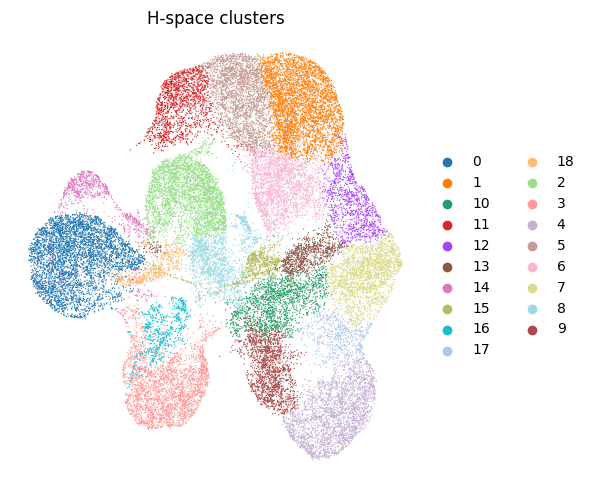

In [6]:
import scknife

fit = scknife.tutorial.load_fit()
fit, clusters = scknife.run_h_graph_clustering_fixed(
    fit, pca_dims=6, n_neighbors=15, resolution=0.5, random_state=42)
clusters.to_csv(scknife.tutorial.output_dir() / "clustering.csv", index=False)
scknife.tutorial.save_fit(fit)
scknife.tutorial.plot_clusters(fit)

Each point is one of the 36,721 cells. The 19 colors identify the Leiden clusters in the fitted factor representation at resolution 0.5.

### Compare clustering settings

To try several settings, use the grid-search function on a copy of the fit. It returns the results for every combination and selects the one with the highest silhouette score. To use a different combination, enter its values in the single-configuration call above.

In [7]:
# trial, grid, best = scknife.run_h_graph_clustering(
#     fit.copy(), pca_dims=[6], neighbors=[15], resolutions=[0.3, 0.5, 0.8],
#     random_state=42)
# grid[["pca_dims", "n_neighbors", "resolution", "n_clusters", "silhouette"]]

## Analysis tasks

Choose any task using the saved model and activities.

### Factor interpretation

The model rank describes how many factors were fitted. Here we group the 24 fitted factors into **four programs** using similarities in their node loadings. The four groups contain 4, 8, 7 and 5 factors, respectively.

In [8]:
import scknife

fit = scknife.tutorial.load_fit()
programs = scknife.fp.group_factors(fit, scknife.tutorial.load_graph(), n_groups=4, bootstraps=200, seed=42)
programs.selected.head()

{'cells': 36721, 'factors': 24, 'selected_k': 4, 'group_sizes': [4, 8, 7, 5], 'bootstraps': 200, 'selected_nodes': 80, 'seconds': 1.6353223323822021, 'cell_id_sha256': '8b8bd7da57111eecb59c5151270a672dae0b27841818cab29e5965b3e69c7868'}


,node_name,node_kind,consensus_cluster,n_cluster_components,mean_z_inside,mean_z_outside,enrichment_delta_z,category_percentile,category_rank,decay_weight,decay_mass_fraction,decay_cumulative_mass,decay_cutoff_rank,category_quota,decay_selected,decay_backfill,selection_reason,cluster_rank
0,SOCS1,gene,0,4,2.008639,-0.401728,2.410367,1.000000,1,1.0,0.181269,0.181269,15,15,True,False,strongest_cluster_decay_prefix,1
1,ADGRE5,cellchat_entity,0,4,1.581558,-0.316312,1.897869,1.000000,1,1.0,0.182092,0.182092,15,15,True,False,strongest_cluster_decay_prefix,2
2,His-Purkinje system development (GO:0003164),GO_term,0,4,1.306926,-0.261385,1.568311,1.000000,1,1.0,0.181269,0.181269,15,15,True,False,strongest_cluster_decay_prefix,3
3,GOLGI_B4GALT_1,reaction,0,4,0.994155,-0.198831,1.192986,0.999365,1,1.0,0.183110,0.183110,15,15,True,False,strongest_cluster_decay_prefix,4
4,HALLMARK_INTERFERON_GAMMA_RESPONSE,geneset,0,4,0.935700,-0.187140,1.122840,1.000000,1,1.0,0.401760,0.401760,3,3,True,False,strongest_cluster_decay_prefix,5


#### Factor usage

<Axes: title={'center': 'Mean H activity by source cell type'}>

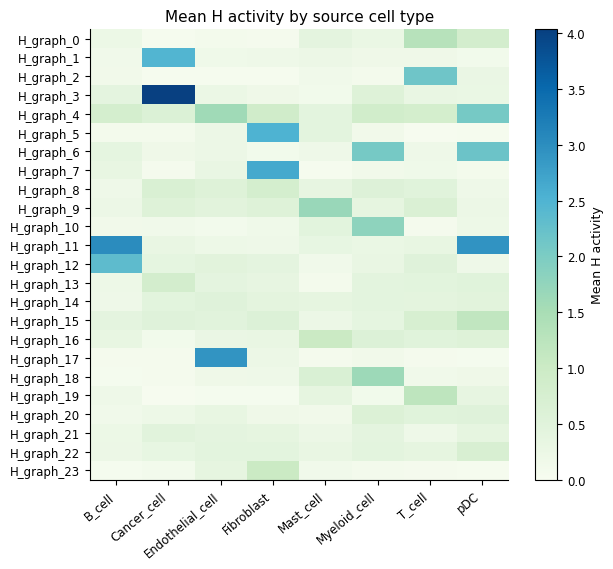

In [9]:
scknife.fp.plot_usage(programs)

Each row is a fitted factor. Color shows its mean H value within each source cell type.

#### Choose a grouping resolution

array([<Axes: title={'center': 'Ambiguous fraction (lower is better)'}, xlabel='Number of factor groups (k)'>,
       <Axes: title={'center': 'Silhouette (higher is better)'}, xlabel='Number of factor groups (k)'>],
      dtype=object)

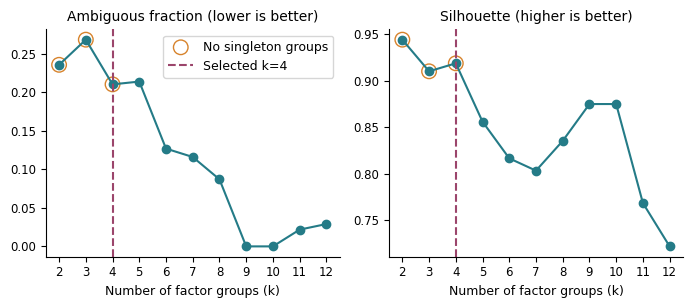

In [10]:
scknife.fp.plot_group_selection(programs)

The curves compare ambiguity and separation as the number of programs changes. The dashed line marks the four-group resolution used here.

#### Consensus membership

<Axes: title={'center': 'Bootstrap factor co-clustering'}>

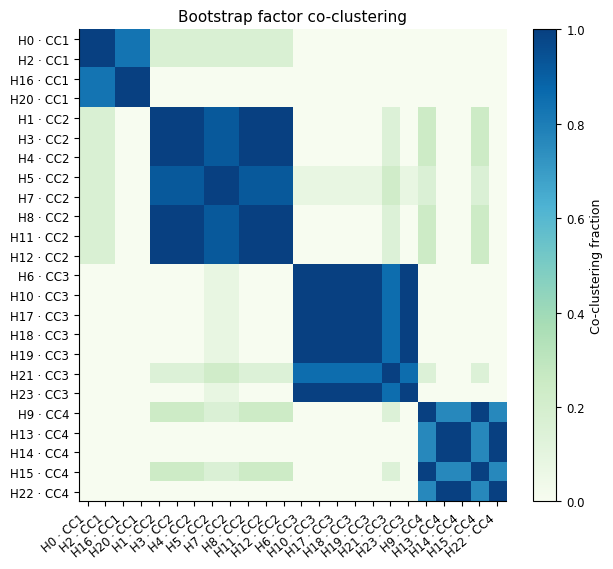

In [11]:
scknife.fp.plot_consensus(programs)

Each tile is the fraction of bootstrap samples in which two factors clustered together.

#### Compare nearby resolutions

<Axes: title={'center': 'Factor membership at nearby resolutions'}>

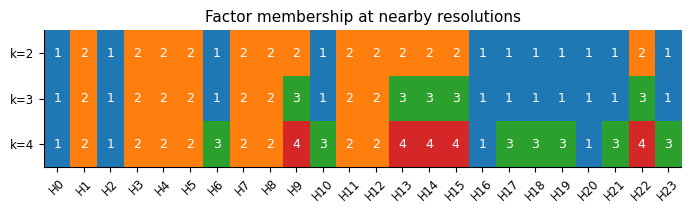

In [12]:
scknife.fp.plot_resolutions(programs)

Compare factor memberships at two, three and four groups. Group numbers are specific to each row.

#### Representative nodes across factors

<Axes: title={'center': 'Biological nodes across factors · NG1–NG4'}>

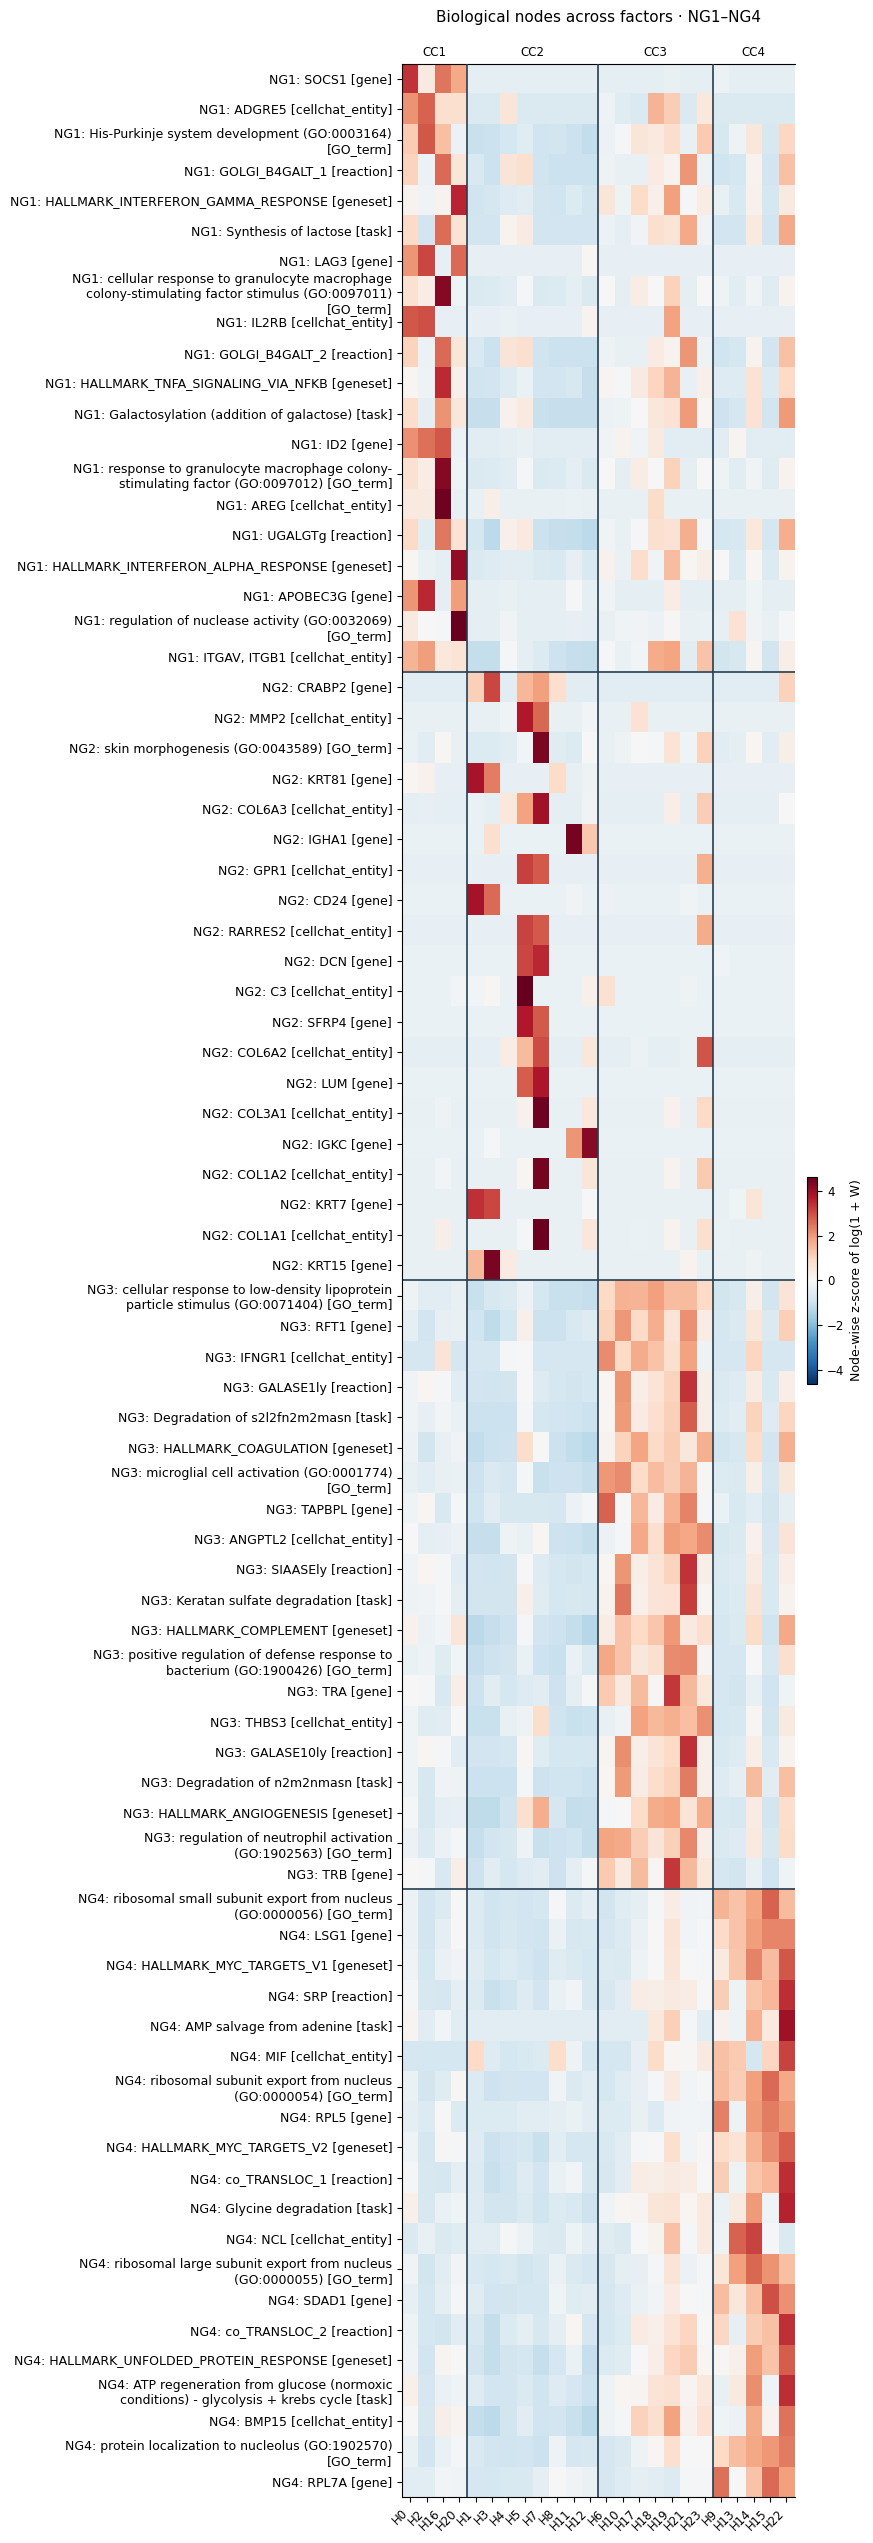

In [13]:
scknife.fp.plot_node_dictionary(programs, by="factor")

Each row is one selected biological node; columns are individual factors ordered by program. Compare relative loadings within a row.

#### Representative nodes across programs

<Axes: title={'center': 'Representative biological nodes · NG1–NG4'}>

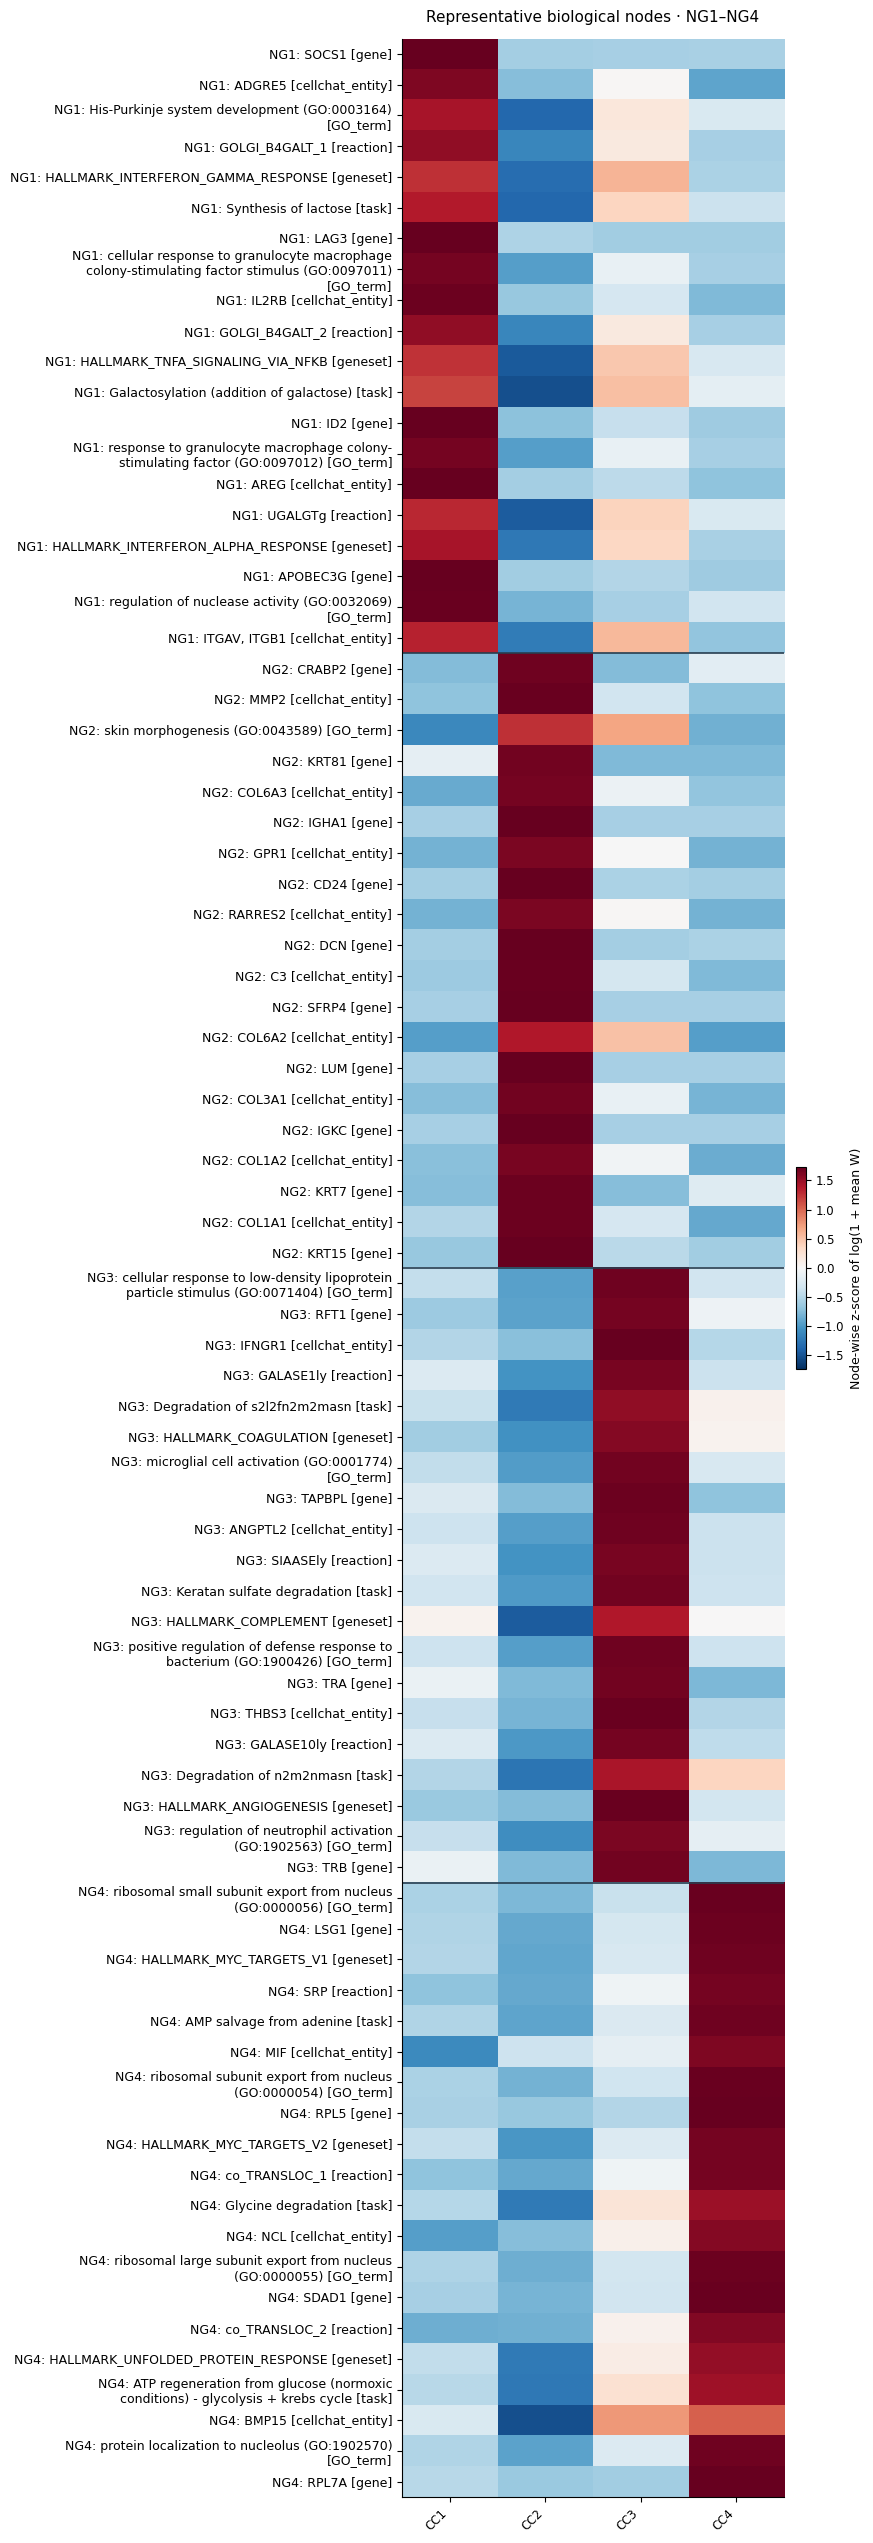

In [14]:
scknife.fp.plot_node_dictionary(programs, by="group")

The same nodes are shown against program-mean loadings. Horizontal lines separate node groups (NGs).

#### Node categories

<Axes: title={'center': 'Biological node-kind composition'}, xlabel='Node group', ylabel='Selected nodes'>

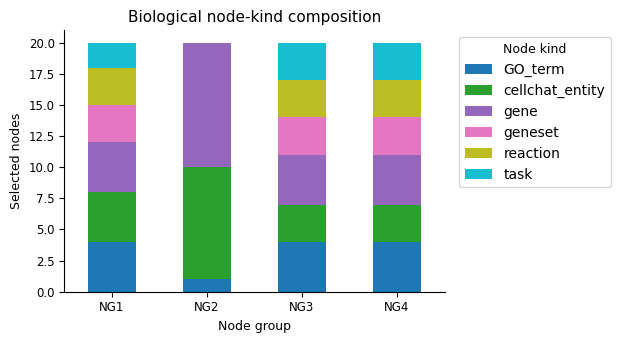

In [15]:
scknife.fp.plot_composition(programs)

The stacked bars count the kinds of biological nodes represented in each program.

#### One entity category

List the available node categories, factor groups (CC) and corresponding node groups (NG).

In [16]:
programs.entity_kinds, programs.groups, programs.ngroups

(['GO_term', 'cellchat_entity', 'gene', 'geneset', 'reaction', 'task'],
 ['CC1', 'CC2', 'CC3', 'CC4'],
 ['NG1', 'NG2', 'NG3', 'NG4'])

Display gene sets across all four programs.

<Axes: title={'center': 'geneset · all programs'}, xlabel='Factors ordered by factor group'>

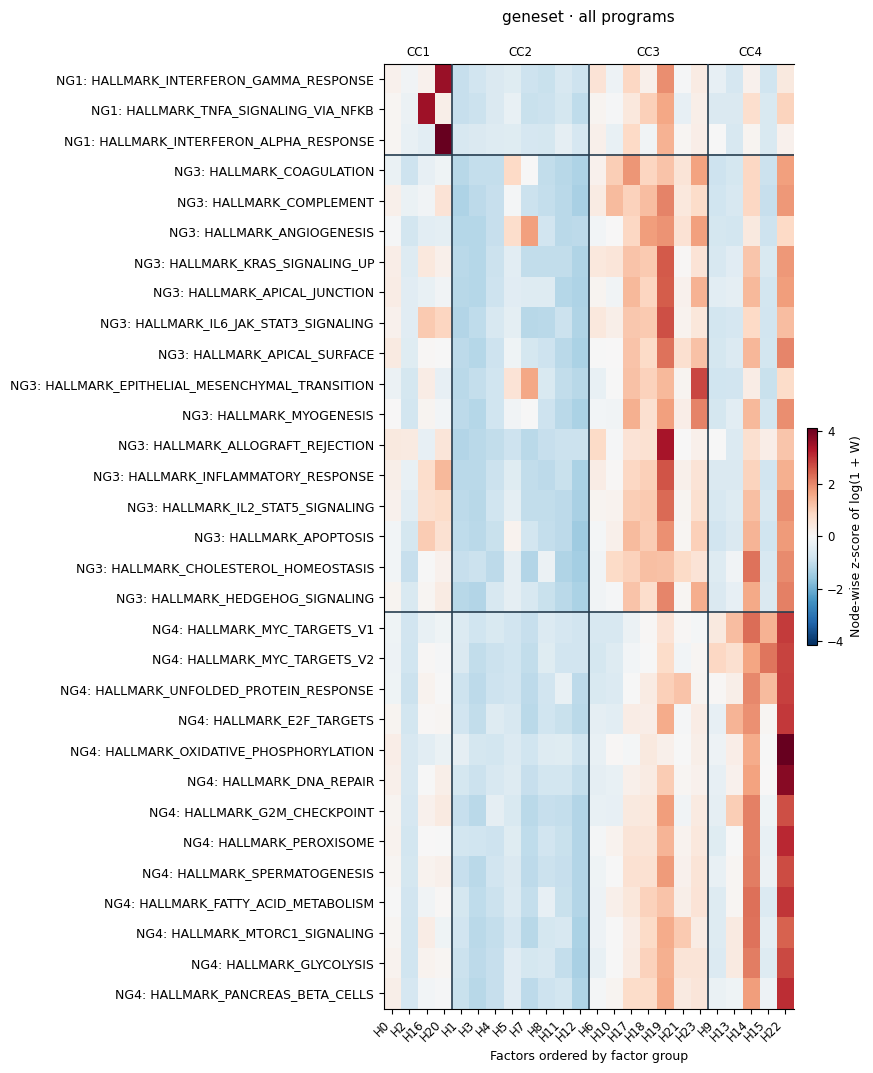

In [17]:
# Other kinds: "gene", "GO_term", "reaction", "task", "cellchat_entity"
scknife.fp.plot_entities(programs, kind="geneset")

Each row is a gene set. Compare its loading profile across the four programs.

#### Node-group activity

<Axes: title={'center': 'Reconstructed node-group activity'}>

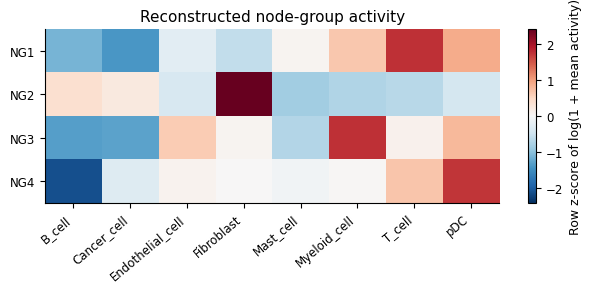

In [18]:
scknife.fp.plot_group_activity(programs, group="NG")

Reconstructed node-group activities are summarized by cell type. Color is standardized within each row.

#### Factor-group activity

<Axes: title={'center': 'Shared W–H factor-group activity'}>

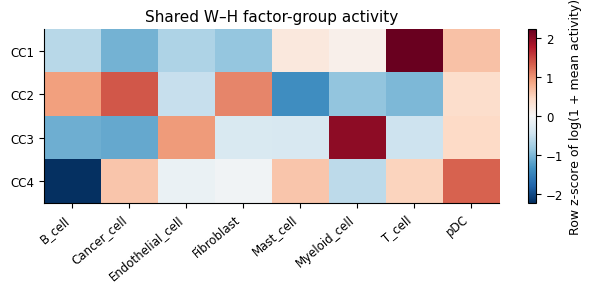

In [19]:
scknife.fp.plot_group_activity(programs, group="CC")

Each row summarizes H activity for the factors in a consensus cluster (CC).

#### Connect nodes, factors and cell types

<Axes: >

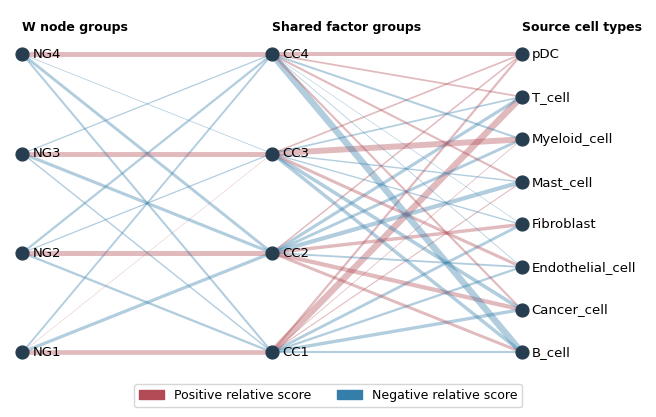

In [20]:
scknife.fp.plot_associations(programs)

Lines connect node groups to factor groups and then to cell types. Their colors show the sign of the relative association.

#### Programs across cells

array([<Axes: >, <Axes: >, <Axes: >,
       <Axes: xlabel='All 36,721 cells · ordered by cell type, patient and timepoint'>],
      dtype=object)

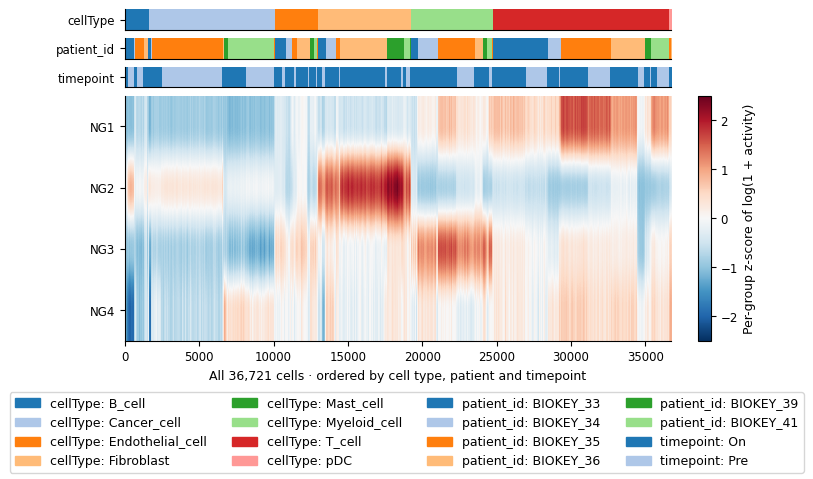

In [21]:
scknife.fp.plot_cell_profiles(programs)

Columns are cells ordered by cell type, patient and timepoint. The top tracks identify those groupings.

#### Patient representation

<Axes: title={'center': 'Cells available per patient and cell type'}>

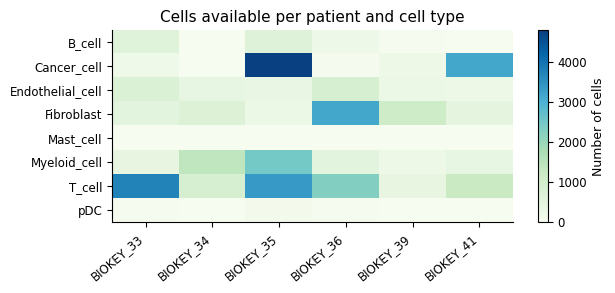

In [22]:
scknife.fp.plot_coverage(programs)

The heatmap counts cells from each patient within each cell type.

#### Selected constituents

array([<Axes: title={'center': 'SOCS1'}, ylabel='log(1 + reconstructed node activity)'>,
       <Axes: title={'center': 'ADGRE5'}, ylabel='log(1 + reconstructed node activity)'>,
       <Axes: title={'center': 'His-Purkinje system\ndevelopment (GO:0003164)'}, ylabel='log(1 + reconstructed node activity)'>],
      dtype=object)

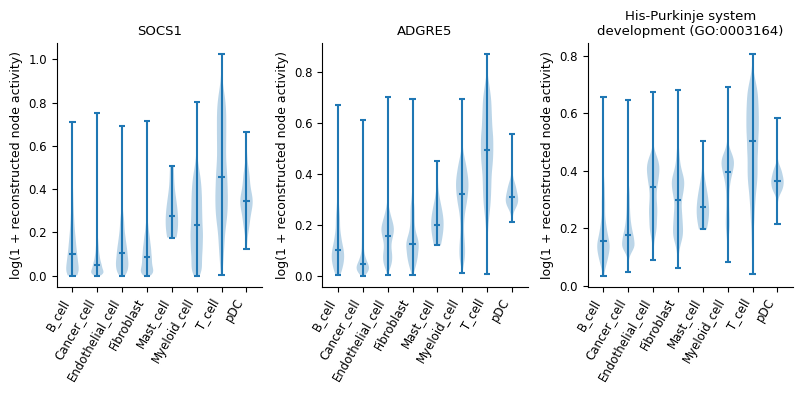

In [23]:
scknife.fp.plot_constituents(programs)

The violins show reconstructed activity for three representative NG1 nodes across cell types.

### Metabolic tasks

Explore task scores on the UMAP and compare metabolic activity between conditions.

#### Calculate MEAI

In [24]:
import scknife

fit = scknife.tutorial.load_fit()
graph = scknife.tutorial.load_graph()
activity = scknife.tutorial.load_activities(fit)
scores = scknife.activity.calculate_meai(activity, graph)
score_name = "MEAI"
# scores, score_name = scknife.activity.node_scores(activity, graph, "task"), "Task-node activity"

MEAI weights task activity by reaction and gene support, then normalizes across tasks within each cell. The two small [human task tables](https://github.com/earmingol/scCellFie/tree/c66c6be030a8ac871d998f17e592477b97781bf9/task_data/homo_sapiens) download on first use.


#### Run the differential activity test

Use the metadata columns for cell type and condition. Here `subset={"expansion": "E"}` selects expanded cells in this dataset. Use `subset=None` to include all cells. With `("Pre", "On")`, positive effects indicate higher activity during treatment. The cell-level Wilcoxon test requires 20 cells per condition and treats cells from the same patient as independent.

In [25]:
comparison = dict(
    cell_type_key="cellType", condition_key="timepoint",
    subset={"expansion": "E"}, contrast=("Pre", "On"), min_cells=20,
)
task_de = scknife.activity.compare_activity(
    fit, scores, kind="task", score_name=score_name, **comparison
)

#### Inspect the results table

Choose a tested cell type and display cutoffs. `passing` contains every highlighted row for its volcano plot, ordered by Benjamini–Hochberg adjusted p-value. Preview the first five.

In [26]:
cell_type = "Cancer_cell"  # Other options: "T_cell", "Myeloid_cell"
cutoffs = dict(q_cutoff=0.05, min_d=0.3, min_log2fc=0.25)
passing = scknife.activity.select_results(task_de, cell_type=cell_type, **cutoffs)
columns = ["cell_type", "feature", "log2FC", "cohens_d", "adj_p_value"]
passing[columns].head().style.format({"log2FC": "{:.3f}", "cohens_d": "{:.3f}", "adj_p_value": "{:.2e}"})

,cell_type,feature,log2FC,cohens_d,adj_p_value
431,Cancer_cell,Co-translational translocation,-0.315,-0.612,8.50e-50
429,Cancer_cell,Disulfide bond formation,-0.437,-0.472,7.64e-48
428,Cancer_cell,Post translational translocation,-0.337,-0.553,2.29e-43
426,Cancer_cell,Synthesis of bilirubin,-0.756,-0.421,2.03e-41
259,Cancer_cell,Malate to pyruvate conversion,0.256,0.525,4.47e-38


Across all cell types, 40 of 1,526 comparisons pass the example cutoffs.

#### Plot the differential results

<Axes: title={'center': 'Metabolic tasks · MEAI · Expanded'}, xlabel="Cohen's d · On minus Pre">

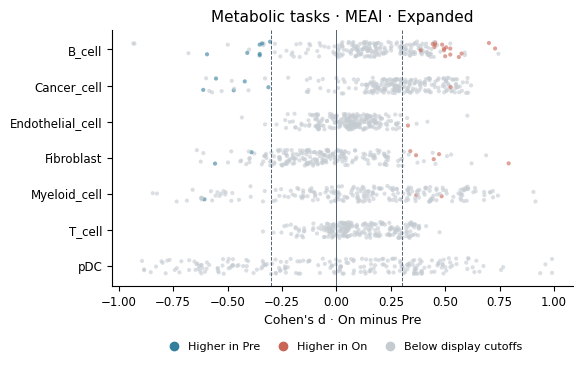

In [27]:
scknife.activity.plot_effects(task_de, **cutoffs)

Each point shows one task’s standardized effect within a cell type. Colored points have adjusted p < 0.05, |Cohen’s d| ≥ 0.3 and |log₂ fold change| ≥ 0.25. Edit `cutoffs` to update the highlights without rerunning the test.

##### Inspect one cell type

<Axes: title={'center': 'Metabolic tasks · MEAI\nCancer_cell · Expanded'}, xlabel="Cohen's d · On minus Pre", ylabel='−log₁₀(BH-adjusted p-value)'>

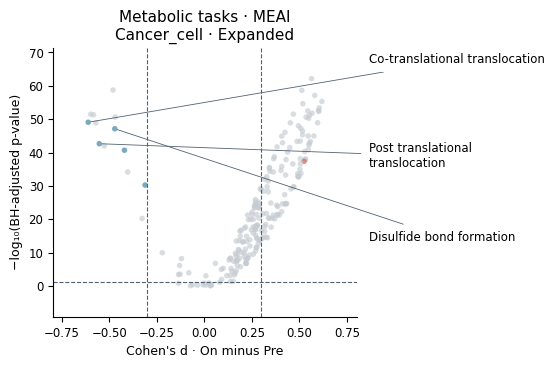

In [28]:
scknife.activity.plot_volcano(task_de, cell_type=cell_type, **cutoffs)

Each point is a tested metabolic task. The guide lines mark the effect-size and adjusted p-value cutoffs. Colored points also pass the absolute log₂ fold-change cutoff. Change `cell_type` or `cutoffs` above to explore the same results.

##### View task activity on the UMAP

array([<Axes: title={'center': 'Glucose to lactate\nconversion'}>,
       <Axes: title={'center': 'GMP salvage from guanine'}>], dtype=object)

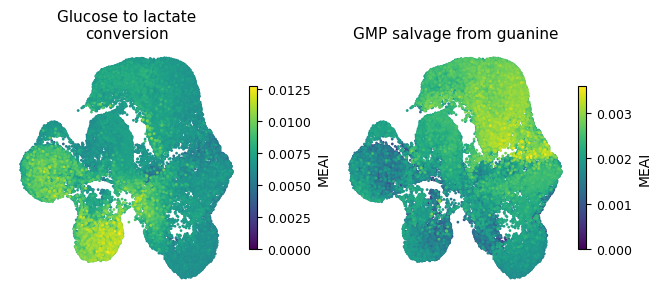

In [29]:
tasks = ["Glucose to lactate conversion", "GMP salvage from guanine"]
# For one panel: tasks = "Mevalonate synthesis"
scknife.tutorial.plot_task_umap(fit, scores, task=tasks, score_name=score_name)

Each panel shows the same cells and coordinates. Brighter colors indicate higher scores within that task; the color limits are separate.

##### Compare one task

<Axes: title={'center': 'GMP salvage from guanine\nCancer cell · Expanded'}, ylabel='MEAI'>

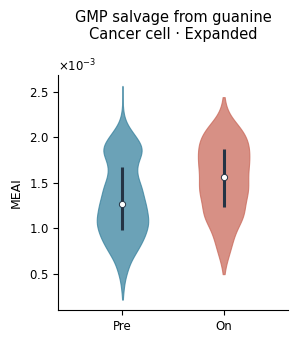

In [30]:
scknife.activity.plot_task_violin(fit, scores, task="GMP salvage from guanine",
                     cell_type=cell_type, score_name=score_name, **comparison)

The white dots mark medians and the dark bars the middle 50% of scores. The example compares cancer cells in the expanded group.

### GO analysis

Compare GO biological-process activities between conditions within each cell type.

#### Load GO activities

In [31]:
import scknife

fit = scknife.tutorial.load_fit()
graph = scknife.tutorial.load_graph()
activity = scknife.tutorial.load_activities(fit)
scores = scknife.activity.node_scores(activity, graph, "GO_term")
score_name = "GO-node activity"

#### Run the differential activity test

Use the metadata columns for cell type and condition. Here `subset={"expansion": "E"}` selects expanded cells in this dataset. Use `subset=None` to include all cells. With `("Pre", "On")`, positive effects indicate higher activity during treatment. The cell-level Wilcoxon test requires 20 cells per condition and treats cells from the same patient as independent.

In [32]:
comparison = dict(
    cell_type_key="cellType", condition_key="timepoint",
    subset={"expansion": "E"}, contrast=("Pre", "On"), min_cells=20,
)
go_de = scknife.activity.compare_activity(
    fit, scores, kind="GO_term", score_name=score_name, **comparison
)

#### Inspect the results table

Choose a tested cell type and display cutoffs. `passing` contains every highlighted row for its volcano plot, ordered by Benjamini–Hochberg adjusted p-value. Preview the first five.

In [33]:
cell_type = "Cancer_cell"  # Other options: "T_cell", "Myeloid_cell"
cutoffs = dict(q_cutoff=0.05, min_d=0.3, min_log2fc=0.25)
passing = scknife.activity.select_results(go_de, cell_type=cell_type, **cutoffs)
columns = ["cell_type", "feature", "log2FC", "cohens_d", "adj_p_value"]
passing[columns].head().style.format({"log2FC": "{:.3f}", "cohens_d": "{:.3f}", "adj_p_value": "{:.2e}"})

,cell_type,feature,log2FC,cohens_d,adj_p_value
6036,Cancer_cell,tRNA 3'-end processing (GO:0042780),0.310,0.470,5.98e-45
6037,Cancer_cell,5-phosphoribose 1-diphosphate metabolic process (GO:0046391),0.283,0.404,7.61e-44
6038,Cancer_cell,5-phosphoribose 1-diphosphate biosynthetic process (GO:0006015),0.283,0.404,7.61e-44
6039,Cancer_cell,ruffle assembly (GO:0097178),0.286,0.452,9.37e-43
6040,Cancer_cell,mitochondrial tRNA processing (GO:0090646),0.286,0.468,1.07e-42


Across all cell types, 5,601 of 42,252 comparisons pass the example cutoffs.

#### Plot the differential results

<Axes: title={'center': 'GO biological processes · Expanded'}, xlabel="Cohen's d · On minus Pre">

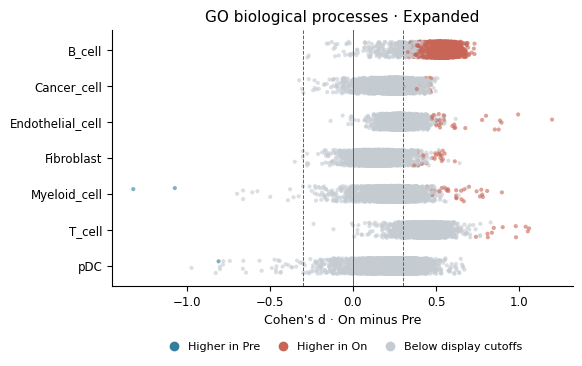

In [34]:
scknife.activity.plot_effects(go_de, **cutoffs)

Each point shows one GO term’s standardized effect within a cell type. Colored points pass the adjusted p-value, absolute effect-size and absolute log₂ fold-change cutoffs.

##### Inspect one cell type

<Axes: title={'center': 'GO biological processes\nCancer_cell · Expanded'}, xlabel="Cohen's d · On minus Pre", ylabel='−log₁₀(BH-adjusted p-value)'>

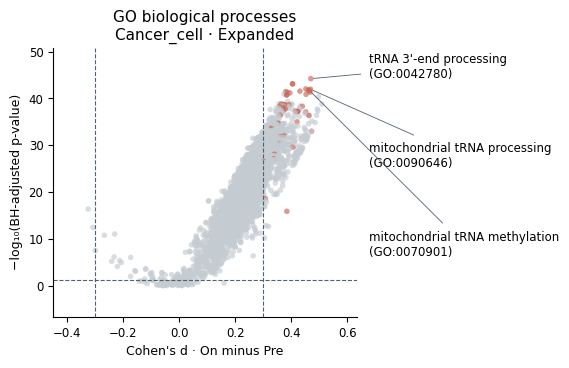

In [35]:
scknife.activity.plot_volcano(go_de, cell_type=cell_type, **cutoffs)

Each point is a tested GO term. The guide lines mark the effect-size and adjusted p-value cutoffs. Colored points also pass the absolute log₂ fold-change cutoff. Change `cell_type` or `cutoffs` above to explore the same results.

### Cell–cell signaling

Explore sender–receiver scores, ligand–receptor contributions and a pathway of interest. The first run prepares the interaction table using R and internet access.

In [36]:
import scknife

fit = scknife.tutorial.load_fit()
activity_path = scknife.tutorial.output_dir() / "activity_scores.parquet"
signals = scknife.communication.score_signaling(fit, activity_path=activity_path, groupby="cellType")

  activity columns 256/36,721


  activity columns 512/36,721


  activity columns 768/36,721


  activity columns 1,024/36,721


  activity columns 1,280/36,721


  activity columns 1,536/36,721


... (134 outputs left out)

  activity columns 36,096/36,721


  activity columns 36,352/36,721


  activity columns 36,608/36,721


  activity columns 36,721/36,721


#### Sender–receiver activity

<Axes: title={'center': 'Sender–receiver activity'}, xlabel='Receiver cell type', ylabel='Sender cell type'>

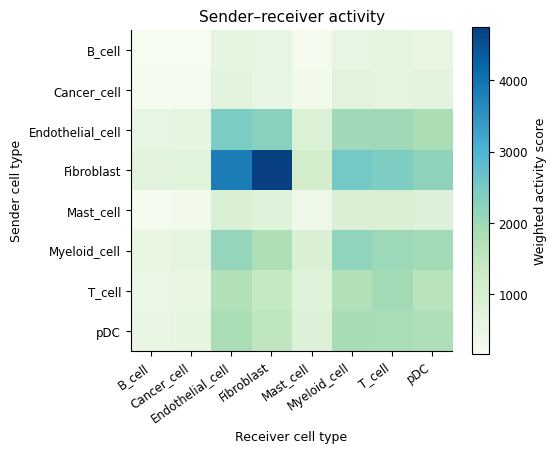

In [37]:
scknife.communication.plot_matrix(signals)

Rows send and columns receive. Color shows the pooled activity-weighted interaction score, including self-links.

#### Outgoing and incoming strength

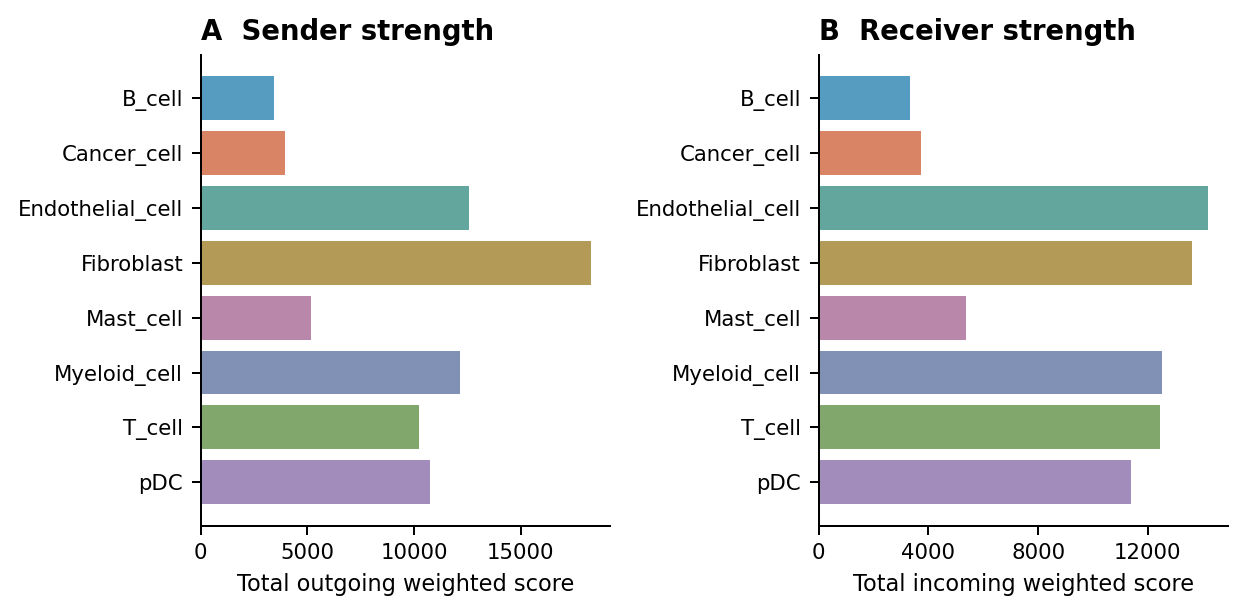

In [38]:
scknife.communication.plot_strength(signals)

Outgoing and incoming scores summarize a cell type’s activity as a sender and receiver.

#### Ligand–receptor contributions

<Axes: title={'center': 'Ligand–receptor contributions'}, xlabel='Sender → receiver', ylabel='Ligand → receptor component'>

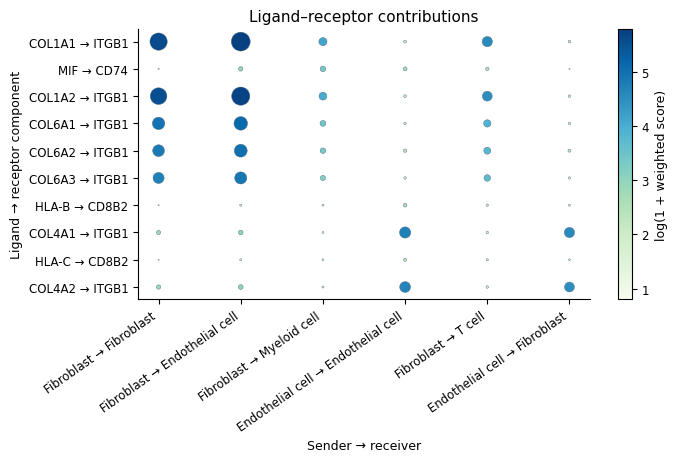

In [39]:
scknife.communication.plot_contributions(signals)

Bubble size shows each component’s weighted contribution within the selected sender–receiver pairs.

#### Permutation support

<Axes: title={'center': 'Cell-label permutation FDR · 1,000 permutations'}, xlabel='Receiver cell type', ylabel='Sender cell type'>

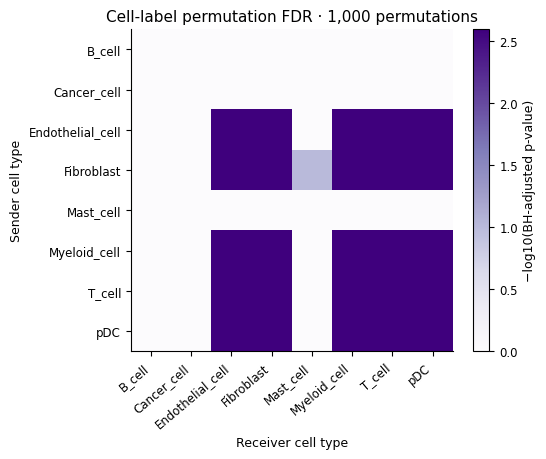

In [40]:
fdr = scknife.communication.permutation_fdr(signals, n_permutations=1000)
scknife.communication.plot_fdr(fdr)

Color shows −log₁₀ of the BH-adjusted p-value across sender–receiver totals. In this cohort, 25 of the 64 pairs have adjusted p < 0.05. Shuffling cell labels retains group sizes and uses the observed specificity.

#### Signaling network

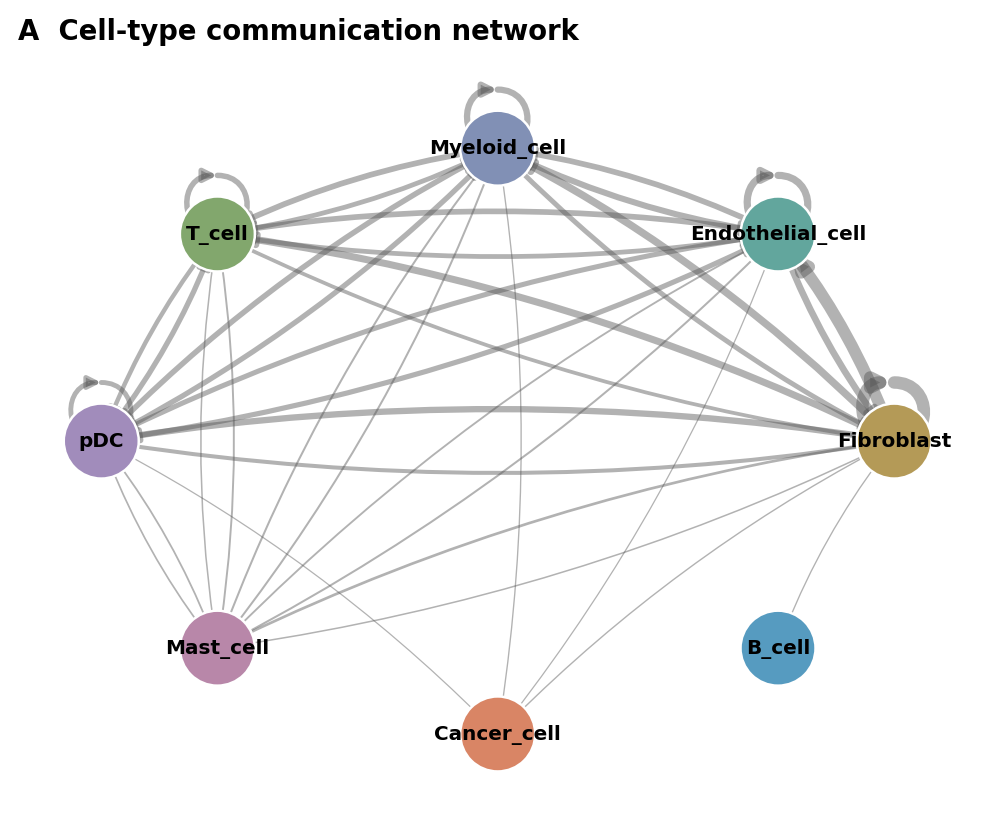

In [41]:
scknife.communication.plot_network(signals)

Arrows show signaling direction for up to 40 positive links. Wider lines indicate stronger scores.

#### Network centrality

array([[<Axes: title={'center': 'Outgoing Strength'}, xlabel='Score'>,
        <Axes: title={'center': 'Incoming Strength'}, xlabel='Score'>],
       [<Axes: title={'center': 'Betweenness'}, xlabel='Score'>,
        <Axes: title={'center': 'Pagerank'}, xlabel='Score'>]],
      dtype=object)

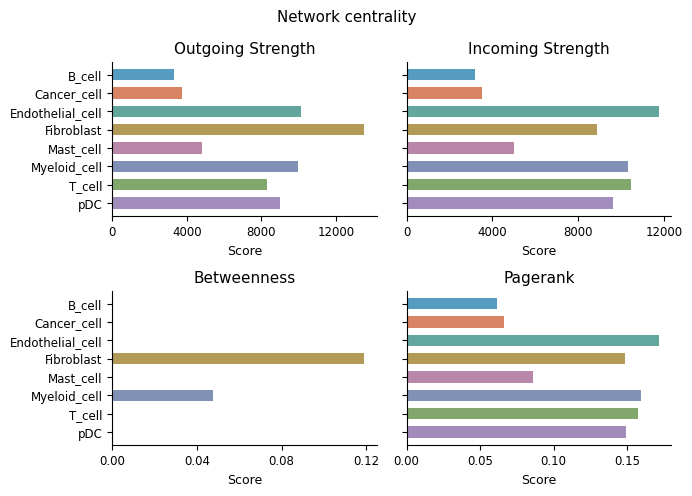

In [42]:
central = scknife.communication.centrality(signals)
scknife.communication.plot_centrality(central)

Strength, betweenness and PageRank summarize the network after self-links are removed.

#### Pathway example: VEGF

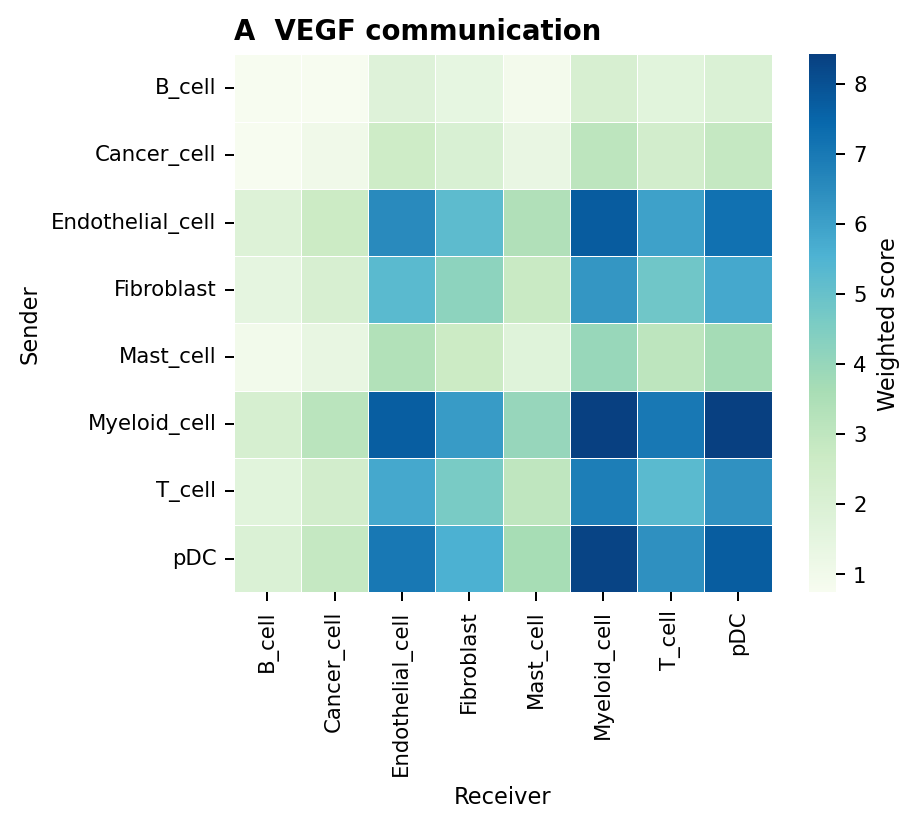

In [43]:
pathway = "VEGF"
# Other pathways: "CXCL", "TGFb", "WNT"
matrix, pairs = scknife.communication.pathway_scores(signals, pathway)
scknife.communication.plot_pathway(matrix, pathway)

Compare sender–receiver scores within VEGF. The permutation test above applies to global totals, not to individual pathways.

#### Pathway contributors

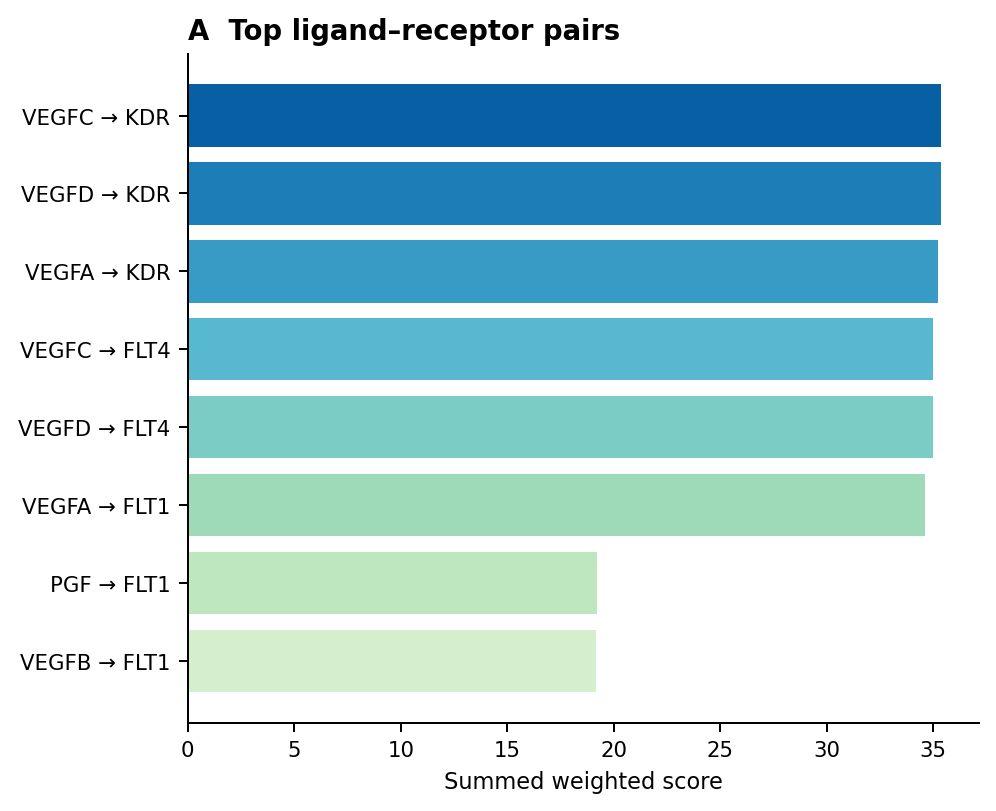

In [44]:
scknife.communication.plot_pathway_pairs(pairs, pathway)

Bars rank ligand–receptor pairs by total weighted score in the selected pathway.

## Optional examples

### Optional: cell-state programs

#### Activity across clusters

<Axes: title={'center': 'Cell-state program activity'}, xlabel='H-space cluster'>

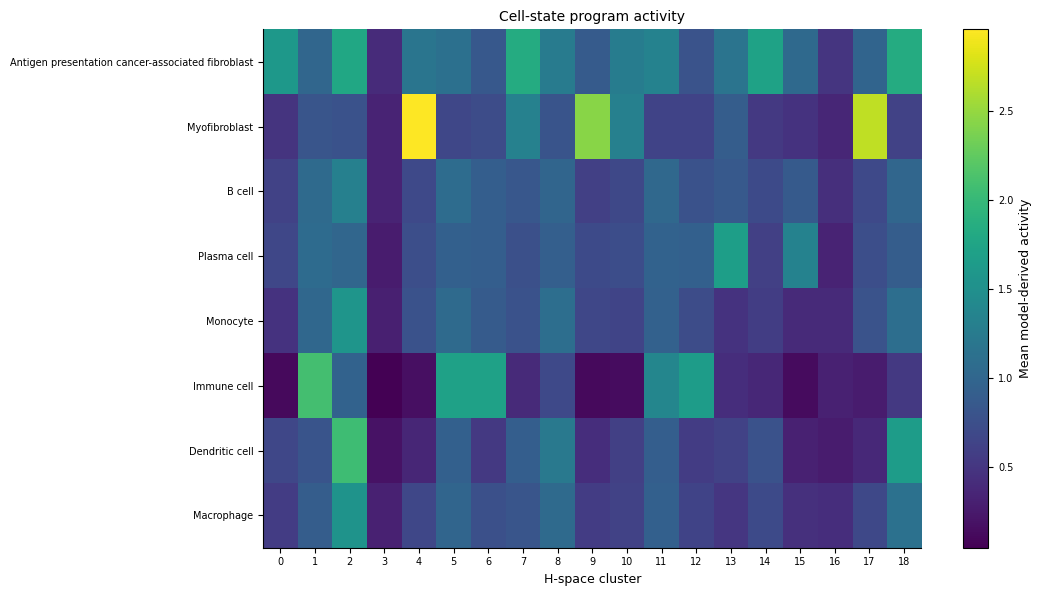

In [45]:
import scknife

fit = scknife.tutorial.load_fit()
means = scknife.optional.state_programs(fit, scknife.tutorial.load_activities(fit), scknife.tutorial.load_graph(), n=8)
scknife.optional.plot_states(means)

Rows are the eight state programs with highest pooled mean activity. Color shows their mean activity in each cluster.

### Optional: rank sensitivity and H projection

Fit on 29,376 cells and project the other 7,345 onto each learned basis with nonnegative least squares.

#### Compare ranks

<Axes: title={'center': 'Exploratory rank sensitivity · 7,345 held-out cells'}, xlabel='Number of factors', ylabel='Held-out relative reconstruction error'>

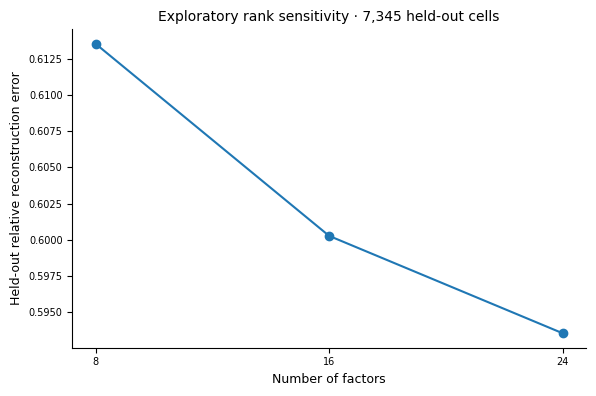

In [46]:
import scknife

errors = scknife.optional.rank_projection(scknife.tutorial.load_fit(), scknife.tutorial.load_graph(), ranks=(8,16,24))
scknife.optional.plot_projection(errors)

Relative reconstruction errors are 0.61355, 0.60027 and 0.59354 at ranks 8, 16 and 24, respectively. Because this split overlaps gene selection and tuning, use it as a projection example rather than an independent performance estimate.